# Validação da umidade relativa da base INPE

Este notebook identifica valores de umidade relativa acima de 100%, considerados fisicamente inválidos, substitui-os temporariamente por valores ausentes (`NaN`) e remove essas linhas da base final.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

def encontrar_pasta_2026(inicio=Path.cwd()):
    inicio = inicio.resolve()
    for pasta in (inicio, *inicio.parents):
        candidata = pasta / '2026'
        if candidata.exists():
            return candidata
    raise FileNotFoundError('Pasta 2026 não encontrada a partir do diretório atual.')

PASTA_2026 = encontrar_pasta_2026()
PASTA_DADOS = PASTA_2026 / 'visualizacoes_comparativas_bases' / 'dados_padronizados'
ARQUIVO_ENTRADA = PASTA_DADOS / 'inpe_2024-08-28_11h_continua.xlsx'
ARQUIVO_SAIDA_XLSX = PASTA_DADOS / 'inpe_2024-08-28_11h_continua_umidade_tratada.xlsx'
ARQUIVO_SAIDA_CSV = PASTA_DADOS / 'inpe_2024-08-28_11h_continua_umidade_tratada.csv'
ARQUIVO_RELATORIO = PASTA_DADOS / 'inpe_2024-08-28_11h_continua_relatorio_umidade.csv'

if not ARQUIVO_ENTRADA.exists():
    raise FileNotFoundError(
        f'Base INPE contínua não encontrada: {ARQUIVO_ENTRADA}. '
        'Execute primeiro a etapa de período contínuo em visualizar_comparar_bases.ipynb.'
    )

In [2]:
dados = pd.read_excel(ARQUIVO_ENTRADA)

colunas_necessarias = ['data_hora', 'radiacao_onda_curta', 'temperatura', 'umidade_relativa']
ausentes = [coluna for coluna in colunas_necessarias if coluna not in dados.columns]
if ausentes:
    raise ValueError(f'Colunas ausentes na base INPE: {ausentes}')

dados['data_hora'] = pd.to_datetime(dados['data_hora'], errors='coerce')
dados['umidade_relativa'] = pd.to_numeric(dados['umidade_relativa'], errors='coerce')

LIMITE_SUPERIOR_UMIDADE = 100.0
umidade_maxima_antes = dados['umidade_relativa'].max()
mascara_invalida = dados['umidade_relativa'] > LIMITE_SUPERIOR_UMIDADE
registros_invalidos = dados.loc[mascara_invalida].copy()
dados.loc[mascara_invalida, 'umidade_relativa'] = float('nan')
dados = dados.dropna(subset=['umidade_relativa']).reset_index(drop=True)

relatorio = pd.DataFrame({
    'indicador': [
        'linhas_na_base',
        'registros_umidade_acima_de_100',
        'umidade_maxima_antes',
        'umidade_maxima_depois',
        'linhas_removidas_por_umidade_invalida',
        'valores_ausentes_umidade_depois',
    ],
    'valor': [
        len(dados),
        len(registros_invalidos),
        umidade_maxima_antes,
        dados['umidade_relativa'].max(),
        len(registros_invalidos),
        dados['umidade_relativa'].isna().sum(),
    ],
})

dados.to_excel(ARQUIVO_SAIDA_XLSX, index=False)
dados.to_csv(ARQUIVO_SAIDA_CSV, index=False)
relatorio.to_csv(ARQUIVO_RELATORIO, index=False)

print(f'Registros de umidade acima de 100% tratados como NaN e removidos: {len(registros_invalidos)}')
print(f'Base validada salva em: {ARQUIVO_SAIDA_XLSX}')
print(f'Relatório salvo em: {ARQUIVO_RELATORIO}')

display(relatorio)
display(registros_invalidos.head(10))
display(dados.describe(include='all'))

Registros de umidade acima de 100% tratados como NaN e removidos: 592
Base validada salva em: C:\Users\sarah\OneDrive\Documentos\Sarah - FILES\Iniciação Cientifica - INPE\2026\visualizacoes_comparativas_bases\dados_padronizados\inpe_2024-08-28_11h_continua_umidade_tratada.xlsx
Relatório salvo em: C:\Users\sarah\OneDrive\Documentos\Sarah - FILES\Iniciação Cientifica - INPE\2026\visualizacoes_comparativas_bases\dados_padronizados\inpe_2024-08-28_11h_continua_relatorio_umidade.csv


,indicador,valor
0,linhas_na_base,3420.0
1,registros_umidade_acima_de_100,592.0
2,umidade_maxima_antes,100.5
3,umidade_maxima_depois,100.0
4,linhas_removidas_por_umidade_invalida,592.0
5,valores_ausentes_umidade_depois,0.0


,data_hora,radiacao_onda_curta,temperatura,umidade_relativa
5,2024-08-28 16:00:00,449.8,24.77,100.3
27,2024-08-29 14:00:00,760.6,25.31,100.3
28,2024-08-29 15:00:00,629.7,26.18,100.3
29,2024-08-29 16:00:00,430.6,26.58,100.3
30,2024-08-29 17:00:00,207.6,25.71,100.3
49,2024-08-30 12:00:00,841.0,26.83,100.3
50,2024-08-30 13:00:00,838.0,28.44,100.3
51,2024-08-30 14:00:00,777.6,30.07,100.3
52,2024-08-30 15:00:00,646.0,30.55,100.3
53,2024-08-30 16:00:00,443.4,30.73,100.3


,data_hora,radiacao_onda_curta,temperatura,umidade_relativa
count,3420,3420.000000,3420.000000,3420.000000
mean,2024-11-24 12:16:46.315789,184.738430,22.882108,54.714305
min,2024-08-28 11:00:00,0.000000,10.870000,0.290000
25%,2024-10-20 08:45:00,0.000000,20.320000,0.359000
50%,2024-11-27 03:30:00,2.157500,22.210000,66.810000
75%,2025-01-01 19:15:00,269.675000,24.760000,87.300000
max,2025-02-11 09:00:00,1097.000000,35.190000,100.000000
std,NaN,294.873772,3.993287,37.028946


## Gráficos da base INPE com umidade tratada

A figura apresenta as médias diárias de radiação de onda curta, temperatura e umidade relativa após a remoção dos registros de umidade acima de 100%.

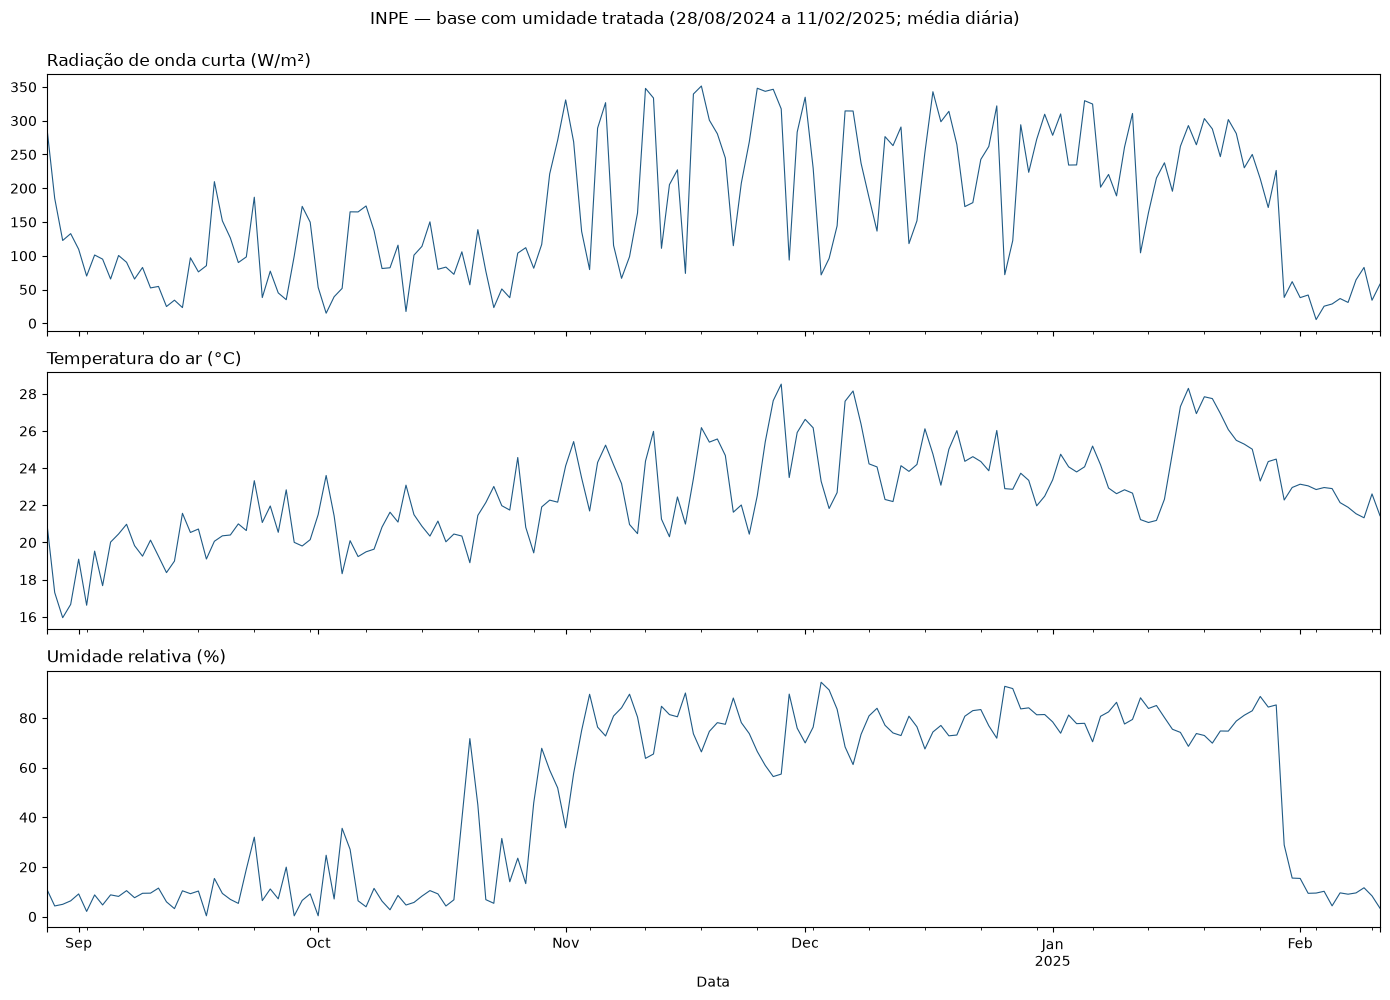

Figura salva em: C:\Users\sarah\OneDrive\Documentos\Sarah - FILES\Iniciação Cientifica - INPE\2026\visualizacoes_comparativas_bases\figuras_por_fonte\inpe_2024-08-28_11h_continua_umidade_tratada_evolucao.png


In [3]:
ROTULOS = {
    'radiacao_onda_curta': 'Radiação de onda curta (W/m²)',
    'temperatura': 'Temperatura do ar (°C)',
    'umidade_relativa': 'Umidade relativa (%)',
}
FREQUENCIA_VISUAL = 'D'
PASTA_FIGURAS = PASTA_2026 / 'visualizacoes_comparativas_bases' / 'figuras_por_fonte'
PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)

def serie_visual(dados, coluna):
    return dados.set_index('data_hora')[coluna].resample(FREQUENCIA_VISUAL).mean()

def plotar_evolucao_inpe(dados, arquivo):
    colunas = ['radiacao_onda_curta', 'temperatura', 'umidade_relativa']
    fig, eixos = plt.subplots(len(colunas), 1, figsize=(14, 10), sharex=True)

    for eixo, coluna in zip(eixos, colunas):
        serie_visual(dados, coluna).plot(ax=eixo, color='#1f5a85', linewidth=0.8)
        eixo.set_title(ROTULOS[coluna], loc='left')
        eixo.set_xlabel('')
        eixo.set_ylabel('')

    inicio = dados['data_hora'].min().strftime('%d/%m/%Y')
    fim = dados['data_hora'].max().strftime('%d/%m/%Y')
    eixos[-1].set_xlabel('Data')
    fig.suptitle(f'INPE — base com umidade tratada ({inicio} a {fim}; média diária)', y=0.995)
    fig.tight_layout()
    fig.savefig(arquivo, bbox_inches='tight')
    plt.show()
    plt.close(fig)

arquivo_figura = PASTA_FIGURAS / 'inpe_2024-08-28_11h_continua_umidade_tratada_evolucao.png'
plotar_evolucao_inpe(dados, arquivo_figura)
print(f'Figura salva em: {arquivo_figura}')